# Konwolucja i korelacja obrazu

**Autor:** Jakub Psarski <br />
**Data:** 21.10.2026

Program implementuje konwolucję i korelację oraz pokazuje ich działanie na obrazie Lena. Następnie korelacja znormalizowana (NCC) jest użyta do znalezienia fragmentu obrazu (template matching) oraz do wyszukiwania najbardziej podobnych emotikon w bazie obrazów.

## Importy i parametry

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
from skimage import io

LENA_URL = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/lena.jpg"
np.random.seed(0)

## Funkcje pomocnicze

In [2]:
def correlate(image, kernel):
    kh, kw = kernel.shape
    padded = np.pad(image, ((kh // 2, kh - 1 - kh // 2), (kw // 2, kw - 1 - kw // 2)))
    windows = sliding_window_view(padded, kernel.shape)
    return np.einsum("xyij,ij->xy", windows, kernel)


def convolve(image, kernel):
    return correlate(image, kernel[::-1, ::-1])


def ncc(image, template):
    windows = sliding_window_view(image, template.shape)
    t = template - template.mean()
    num = np.einsum("xyij,ij->xy", windows, t)
    s = windows.sum(axis=(2, 3))
    s2 = np.einsum("xyij,xyij->xy", windows, windows)
    var = s2 - s**2 / t.size
    return num / (np.sqrt(np.maximum(var, 0) * (t**2).sum()) + 1e-9)


def show(images, titles):
    plt.figure(figsize=(5 * len(images), 5))
    for i, (im, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        plt.imshow(im, cmap="gray")
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

def show2by2(images, titles):
    plt.figure(figsize=(5 * len(images) // 2, 5 * len(images) // 2))
    for i, (im, title) in enumerate(zip(images, titles)):
        plt.subplot(len(images) // 2, len(images) // 2, i + 1)
        plt.imshow(im, cmap="gray")
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

## Wczytanie obrazu

In [3]:
img = io.imread(LENA_URL, as_gray=True) * 255
print("image size:", img.shape)

image size: (512, 512)


## Konwolucja – rozmycie i wykrywanie krawędzi

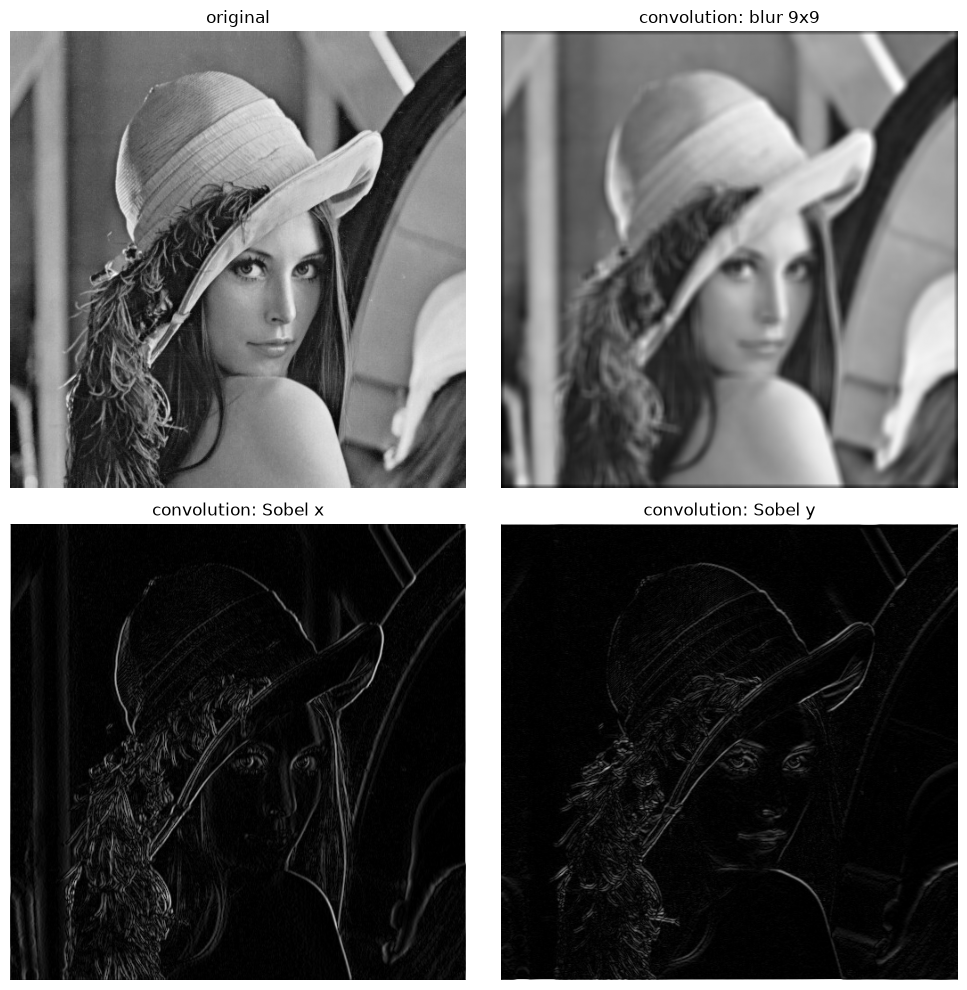

In [4]:
blur = np.ones((9, 9)) / 81
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float64)
sobel_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float64)

blurred = convolve(img, blur)
edges_x = np.abs(convolve(img, sobel_x))
edges_y = np.abs(convolve(img, sobel_y))

show2by2([img, blurred, edges_x, edges_y], ["original", "convolution: blur 9x9", "convolution: Sobel x", "convolution: Sobel y"])

## Porównanie konwolucji i korelacji

convolution == correlation with flipped kernel: True


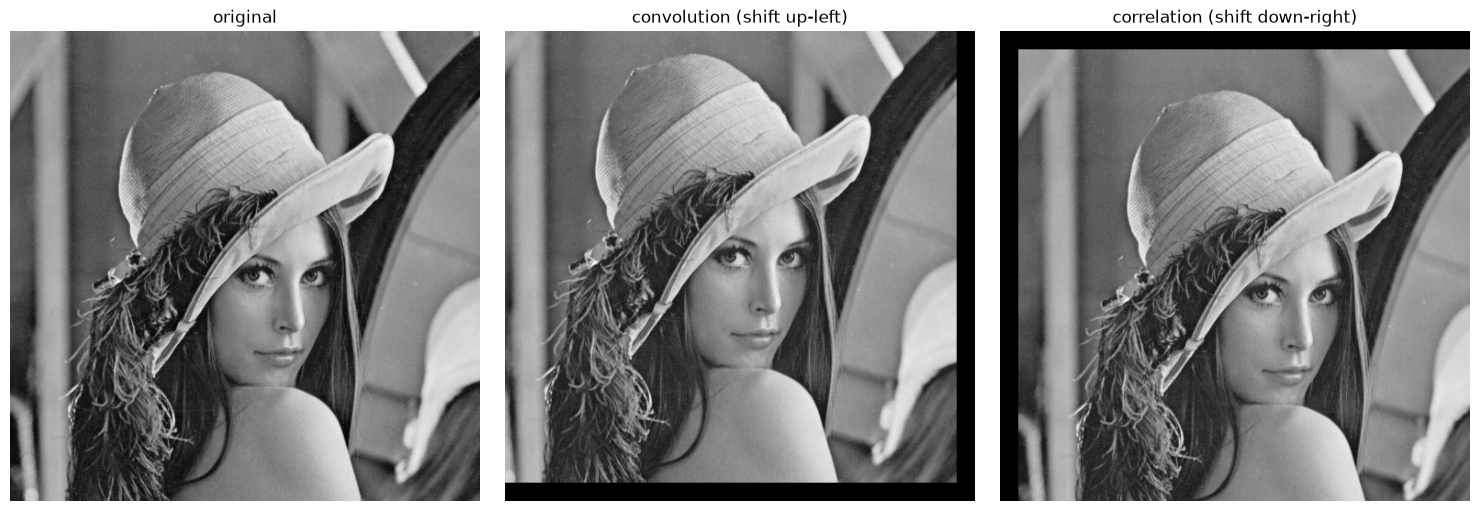

In [5]:
shift = np.zeros((41, 41))
shift[0, 0] = 1

conv = convolve(img, shift)
corr = correlate(img, shift)

print("convolution == correlation with flipped kernel:", np.allclose(conv, correlate(img, shift[::-1, ::-1])))

show([img, conv, corr], ["original", "convolution (shift up-left)", "correlation (shift down-right)"])

## Korelacja – wyszukiwanie fragmentu obrazu (template matching)

raw correlation: x=457, y=344
NCC: x=250, y=250, NCC=1.0000


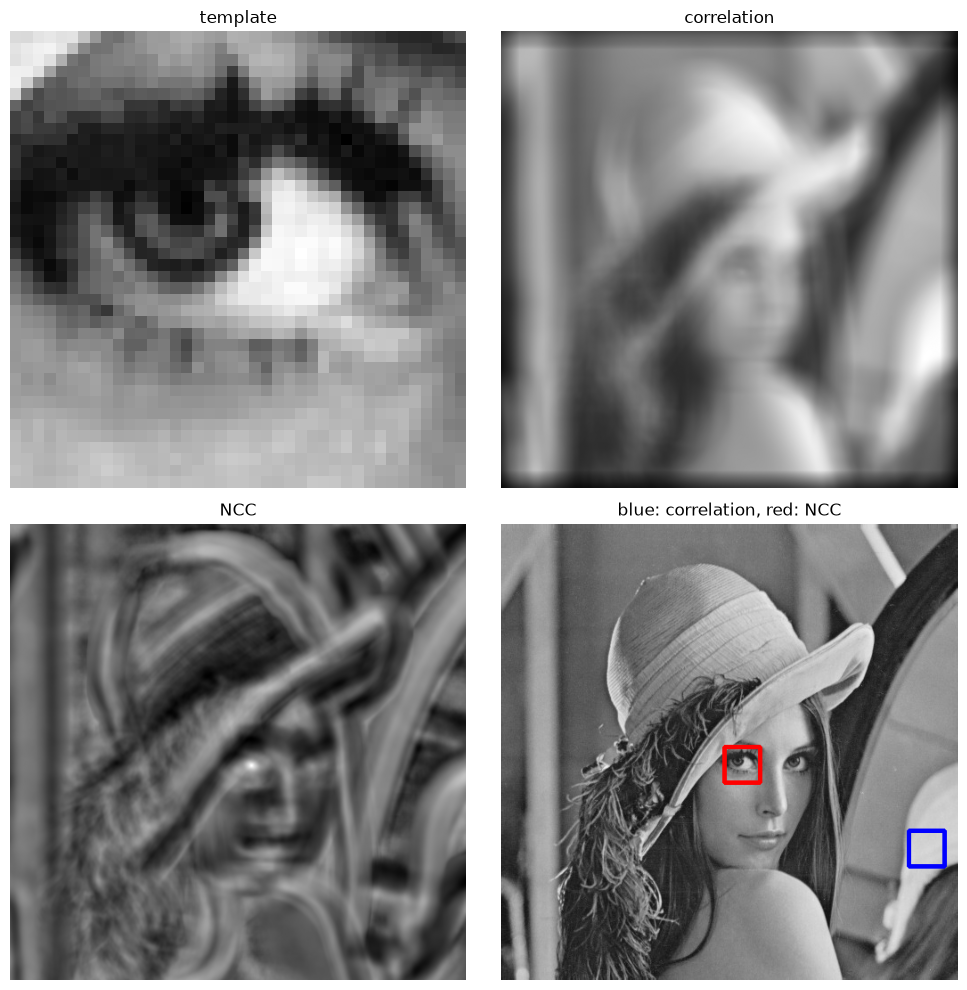

In [6]:
template = img[250:290, 250:290]
th, tw = template.shape

raw = correlate(img, template)
score = ncc(img, template)

ry, rx = np.unravel_index(np.argmax(raw), raw.shape)
ry, rx = ry - th // 2, rx - tw // 2
y, x = np.unravel_index(np.argmax(score), score.shape)
print(f"raw correlation: x={rx}, y={ry}")
print(f"NCC: x={x}, y={y}, NCC={score[y, x]:.4f}")

result = cv2.cvtColor(img.astype(np.uint8), cv2.COLOR_GRAY2RGB)
cv2.rectangle(result, (rx, ry), (rx + tw, ry + th), (0, 0, 255), 3)
cv2.rectangle(result, (x, y), (x + tw, y + th), (255, 0, 0), 3)

show2by2([template, raw, score, result], ["template", "correlation", "NCC", "blue: correlation, red: NCC"])

## Wyszukiwanie najbardziej podobnej emotikony w bazie

In [7]:
def make_emoji(c):
    img = np.zeros((64, 64), np.uint8)
    cv2.circle(img, (32, 32), 24, 255, -1)
    cv2.circle(img, (24, 24), 4, 0, -1)
    cv2.circle(img, (40, 24), 4, 0, -1)
    if c == 0:
        cv2.ellipse(img, (32, 36), (13, 10), 0, 0, 180, 0, -1)
    elif c == 1:
        cv2.ellipse(img, (32, 48), (12, 7), 0, 180, 360, 0, 4)
    elif c == 2:
        cv2.rectangle(img, (21, 40), (43, 44), 0, -1)
    else:
        cv2.circle(img, (32, 42), 7, 0, -1)
    return img


def transform(img):
    M = cv2.getRotationMatrix2D((32, 32), np.random.uniform(-30, 30), np.random.uniform(0.7, 1.1))
    M[0, 1] += np.random.uniform(-0.2, 0.2)
    M[:, 2] += np.random.uniform(-5, 5, 2)
    return cv2.warpAffine(img, M, (64, 64), flags=cv2.INTER_NEAREST)


def similarity(db_img, query):
    return ncc(np.pad(db_img, 16).astype(np.float64), query.astype(np.float64)).max()


names = np.array(["happy", "sad", "neutral", "surprised"])
db_labels = np.repeat(np.arange(4), 100)
db_imgs = np.array([transform(make_emoji(c)) for c in db_labels])
print("database size:", len(db_imgs))

database size: 400


query: happy, found: happy, NCC=0.9325
query: sad, found: sad, NCC=0.9062
query: neutral, found: neutral, NCC=0.9370
query: surprised, found: surprised, NCC=0.9182


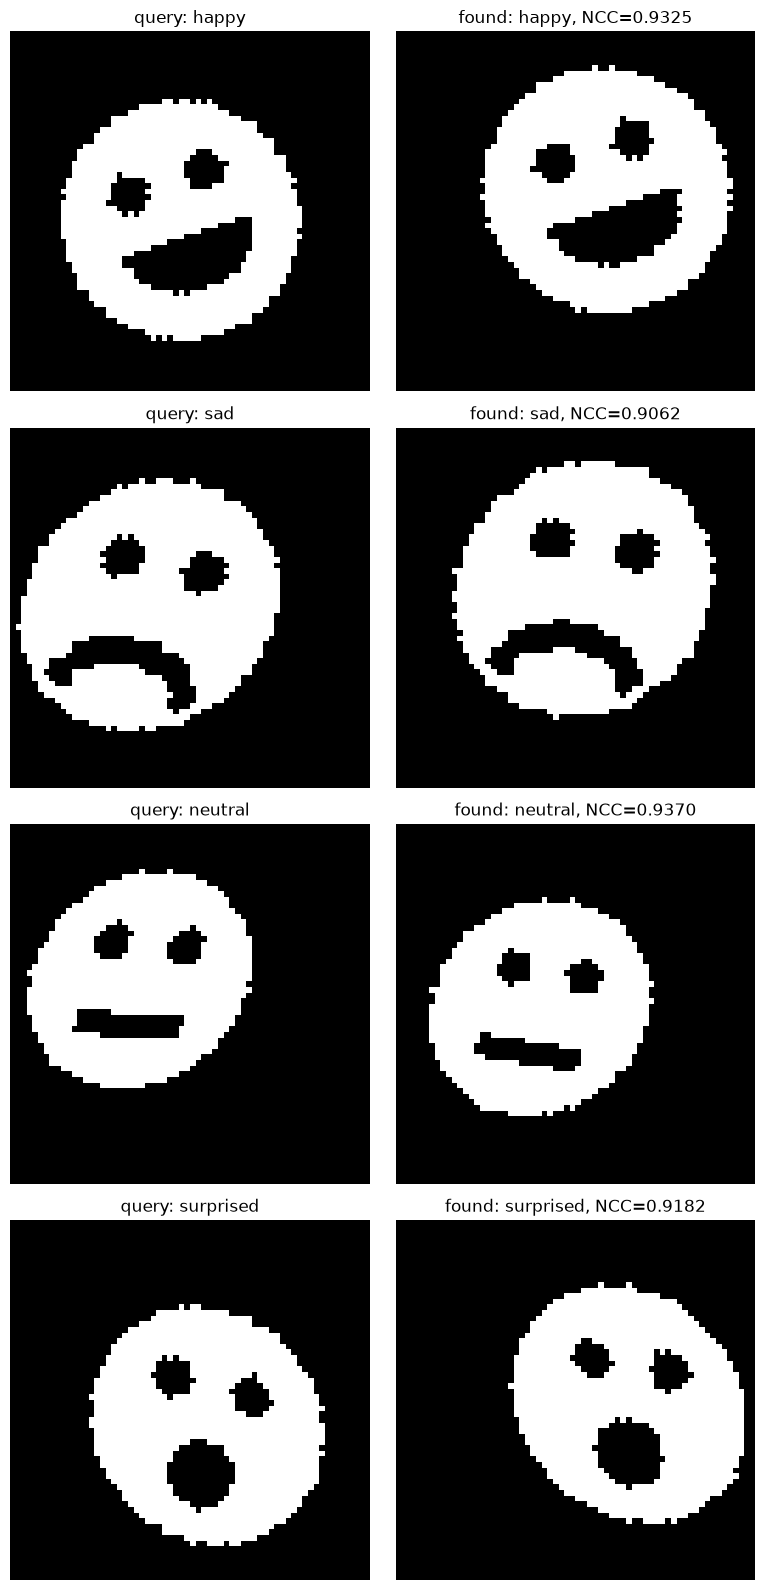

In [8]:
plt.figure(figsize=(8, 16))
for c in range(4):
    query = transform(make_emoji(c))
    scores = np.array([similarity(d, query) for d in db_imgs])
    best = np.argmax(scores)
    print(f"query: {names[c]}, found: {names[db_labels[best]]}, NCC={scores[best]:.4f}")

    plt.subplot(4, 2, 2 * c + 1)
    plt.imshow(query, cmap="gray")
    plt.title("query: " + names[c])
    plt.axis("off")

    plt.subplot(4, 2, 2 * c + 2)
    plt.imshow(db_imgs[best], cmap="gray")
    plt.title(f"found: {names[db_labels[best]]}, NCC={scores[best]:.4f}")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [9]:
correct = 0
for _ in range(50):
    c = np.random.randint(4)
    query = transform(make_emoji(c))
    scores = np.array([similarity(d, query) for d in db_imgs])
    correct += db_labels[np.argmax(scores)] == c
print(f"accuracy: {correct / 50 * 100:.0f}%")

accuracy: 84%


## Wnioski

Konwolucja i korelacja liczą to samo (ważoną sumę pikseli pod maską), różnią się tylko tym, że w konwolucji maska jest obrócona o 180°. Dla masek symetrycznych (rozmycie) wynik jest identyczny, dla niesymetrycznych widać różnicę - maska przesuwająca obraz przesuwa go w przeciwne strony. Zwykła korelacja nie nadaje się do wyszukiwania wzorca, bo największą wartość daje w najjaśniejszym miejscu obrazu (jasny fragment przy prawej krawędzi), a nie tam, gdzie jest wzorzec. Korelacja znormalizowana (NCC) usuwa wpływ jasności i kontrastu i poprawnie znajduje oko (NCC = 1). W wyszukiwaniu emotikon NCC liczona z przesunięciami poprawnie dopasowała wszystkie przykładowe zapytania, a skuteczność na losowych zapytaniach wyniosła 84%. Wszystkie emotikony mają tę samą twarz i różnią się tylko ustami, więc korelacja musi wychwycić małą różnicę. Korelacja jest odporna na przesunięcie, ale nie na obrót i zmianę skali, a przy zakresach obrotu ±30° i skali 0,7-1,1 różnice w położeniu i wielkości twarzy mogą przeważyć nad różnicą w ustach. Dlatego część zapytań jest dopasowywana do niewłaściwej emotikony.